<a href="https://colab.research.google.com/github/Sasha3424/23145/blob/main/26_27_grsu_ml_ind_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Индивидуальная практическая работа 5. Реализация сверточной нейронной сети

Заполните тетрадку.



Обучите сеть для распознования номера дома.
Подробнее можно почитать тут http://ufldl.stanford.edu/housenumbers/


Все ячейки должны быть выполнены и должен быть виден output.

### Часть 1.

Пишем сверточную сеть

In [2]:
!wget -c http://ufldl.stanford.edu/housenumbers/train_32x32.mat http://ufldl.stanford.edu/housenumbers/test_32x32.mat

--2026-11-17 12:20:53--  http://ufldl.stanford.edu/housenumbers/train_32x32.mat
Resolving ufldl.stanford.edu (ufldl.stanford.edu)... 171.64.64.42
Connecting to ufldl.stanford.edu (ufldl.stanford.edu)|171.64.64.42|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://ufldl.stanford.edu/housenumbers/train_32x32.mat [following]
--2026-11-17 12:20:53--  https://ufldl.stanford.edu/housenumbers/train_32x32.mat
Connecting to ufldl.stanford.edu (ufldl.stanford.edu)|171.64.64.42|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 182040794 (174M)
Saving to: ‘train_32x32.mat’

train_32x32.mat     100%[===================>] 173.61M   107MB/s    in 1.6s    

2026-11-17 12:20:55 (107 MB/s) - ‘train_32x32.mat’ saved [182040794/182040794]

URL transformed to HTTPS due to an HSTS policy
--2026-11-17 12:20:55--  https://ufldl.stanford.edu/housenumbers/test_32x32.mat
Reusing existing connection to ufldl.stanford.edu:443.
HTTP request sent

In [3]:
from collections import namedtuple

import matplotlib.pyplot as plt
import numpy as np
import PIL
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.datasets as dset
from torch.utils.data.sampler import SubsetRandomSampler
from torch.optim.lr_scheduler import StepLR
import itertools

from torchvision import transforms

In [4]:
# use GPU if available
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
device

device(type='cuda')

Загружаем данные

Отнормализуйте данные относительно средних

mean=[0.43,0.44,0.47],

std=[0.20,0.20,0.20]

In [5]:
data_train = dset.SVHN('./',
                       transform=transforms.Compose([
                           transforms.ToTensor(),
                           transforms.Normalize(mean=[0.43, 0.44, 0.47],
                                                std=[0.20, 0.20, 0.20]),
                       ])
                      )

data_test = dset.SVHN('./', split='test', transform=transforms.Compose([
                           transforms.ToTensor(),
                           transforms.Normalize(mean=[0.43, 0.44, 0.47],
                                                std=[0.20, 0.20, 0.20]),
                       ]))

Разделяем данные на training и validation.

На всякий случай для подробностей - https://pytorch.org/tutorials/beginner/data_loading_tutorial.html

In [6]:
batch_size = 32

data_size = data_train.data.shape[0]
validation_split = .2
split = int(np.floor(validation_split * data_size))
indices = list(range(data_size))
np.random.shuffle(indices)

train_indices, val_indices = indices[split:], indices[:split]

train_sampler = SubsetRandomSampler(train_indices)
val_sampler = SubsetRandomSampler(val_indices)

train_loader = torch.utils.data.DataLoader(data_train, batch_size=batch_size,
                                           sampler=train_sampler)
val_loader = torch.utils.data.DataLoader(data_train, batch_size=batch_size,
                                         sampler=val_sampler)

In [7]:
# We'll use a special helper module to shape it into a flat tensor
class Flattener(nn.Module):
    def forward(self, x):
        batch_size, *_ = x.shape
        return x.view(batch_size, -1)

Создадим простейшую сеть с новыми слоями:

Convolutional - nn.Conv2d

MaxPool - nn.MaxPool2d

In [8]:
nn_model = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            Flattener(),
            nn.Linear(32 * 8 * 8, 10),
          )

nn_model.to(device, torch.float32)

loss = nn.CrossEntropyLoss().type(torch.cuda.FloatTensor)
optimizer = optim.SGD(nn_model.parameters(), lr=1e-1, weight_decay=1e-4)

In [9]:
def train_model(model, train_loader, val_loader, loss, optimizer, num_epochs,
                scheduler=StepLR(optimizer, step_size=1, gamma=1.0)):
    loss_history = []
    train_history = []
    val_history = []
    for epoch in range(num_epochs):
        scheduler.step()
        model.train()  # Enter train mode

        loss_accum = 0
        correct_samples = 0
        total_samples = 0
        for i_step, (x, y) in enumerate(train_loader):

            x_gpu = x.to(device)
            y_gpu = y.to(device)

            prediction = model(x_gpu)
            loss_value = loss(prediction, y_gpu)

            # START YOUR CODE
            optimizer.zero_grad()       # make zero to optimizer
            loss_value.backward()       # calc backward
            optimizer.step()            # make step
            # END YOUR CODE

            indices = torch.argmax(prediction, 1)
            correct_samples += torch.sum(indices == y_gpu)
            total_samples += y.shape[0]

            loss_accum += loss_value

        ave_loss = loss_accum / (i_step + 1)
        train_accuracy = float(correct_samples) / total_samples
        val_accuracy = compute_accuracy(model, val_loader)

        loss_history.append(float(ave_loss))
        train_history.append(train_accuracy)
        val_history.append(val_accuracy)

        print("Average loss: %f, Train accuracy: %f, Val accuracy: %f"
              % (ave_loss, train_accuracy, val_accuracy))

    return loss_history, train_history, val_history


def compute_accuracy(model, loader):

    model.eval()

    with torch.no_grad():
        correct_samples = 0
        total_samples = 0
        for i_step, (x, y) in enumerate(loader):
            x_gpu = x.to(device)
            y_gpu = y.to(device)

            prediction = model(x_gpu)
            indices = torch.argmax(prediction, 1)
            correct_samples += torch.sum(indices == y_gpu)
            total_samples += y.shape[0]

        val_accuracy = float(correct_samples) / total_samples
    return val_accuracy

In [10]:
loss_history, train_history, val_history = train_model(nn_model, train_loader, val_loader, loss, optimizer, 5)


/tmp/ipykernel_445/3618373730.py:7: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/tmp/ipykernel_445/3618373730.py:37: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  loss_history.append(float(ave_loss))


Average loss: 0.818635, Train accuracy: 0.750452, Val accuracy: 0.840898
Average loss: 0.504287, Train accuracy: 0.852455, Val accuracy: 0.830250
Average loss: 0.452145, Train accuracy: 0.866771, Val accuracy: 0.862945
Average loss: 0.425159, Train accuracy: 0.873801, Val accuracy: 0.862603
Average loss: 0.407097, Train accuracy: 0.878903, Val accuracy: 0.840489


Ожидается Val accuracy > 0.81.

### Часть 2. Добавляем аугментации

С PyTorch идут несколько таких алгоритмов, называемых transforms. Более подробно про них можно прочитать тут - https://pytorch.org/tutorials/beginner/data_loading_tutorial.html#transforms

Ниже мы используем следующие алгоритмы генерации:

ColorJitter - случайное изменение цвета

добавьте еще 2-3 аугментации

In [11]:
tfs = transforms.Compose([
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.43, 0.44, 0.47], std=[0.20, 0.20, 0.20]),
])
# Create augmented train dataset
data_aug_train = dset.SVHN('./',
                       transform=tfs
                      )

train_aug_loader = torch.utils.data.DataLoader(data_aug_train, batch_size=batch_size,
                                           sampler=train_sampler)

Проверьте как выглядят данные после аугментаций

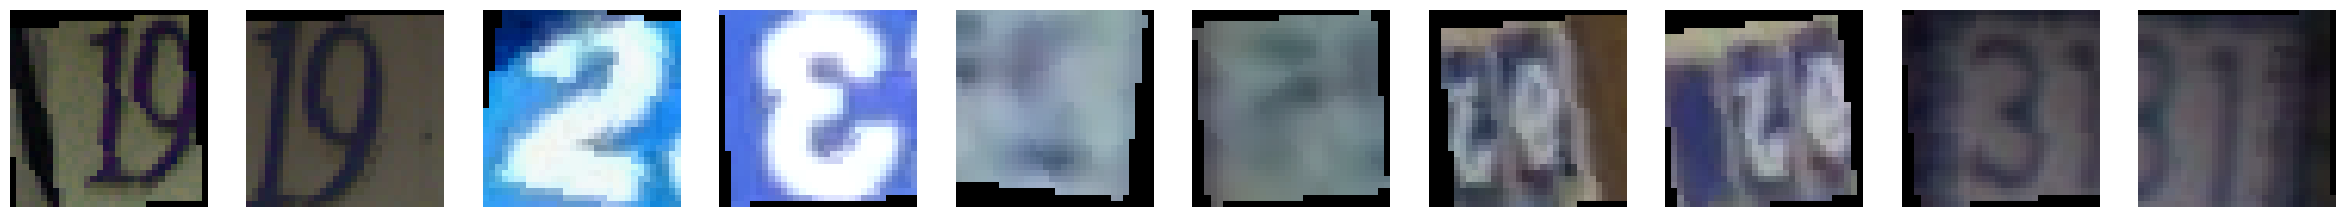

In [12]:
data_aug_vis = dset.SVHN('./', transform=tfs)

mean = torch.tensor([0.43, 0.44, 0.47]).view(3, 1, 1)
std  = torch.tensor([0.20, 0.20, 0.20]).view(3, 1, 1)

plt.figure(figsize=(30, 3))
for i, (x, y) in enumerate(data_aug_vis):
    if i == 10:
        break
    img = x * std + mean           # обратная нормализация
    img = img.clamp(0, 1)          # чтобы не было выхода за [0,1]
    plt.subplot(1, 10, i + 1)
    plt.grid(False)
    plt.imshow(img.permute(1, 2, 0))  # C,H,W -> H,W,C
    plt.axis('off')
plt.show()

Выберите какие подходят

In [15]:
tfs = transforms.Compose([
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.43, 0.44, 0.47], std=[0.20, 0.20, 0.20]),
])

data_aug_train = dset.SVHN('./', transform=tfs)
train_aug_loader = torch.utils.data.DataLoader(data_aug_train, batch_size=batch_size,
                                               sampler=train_sampler)

In [16]:
loss_history, train_history, val_history = train_model(nn_model, train_aug_loader, val_loader, loss, optimizer, 5)


Average loss: 0.763349, Train accuracy: 0.763505, Val accuracy: 0.851205
Average loss: 0.748209, Train accuracy: 0.769546, Val accuracy: 0.830114
Average loss: 0.746037, Train accuracy: 0.769290, Val accuracy: 0.827793
Average loss: 0.739394, Train accuracy: 0.773539, Val accuracy: 0.849703
Average loss: 0.734728, Train accuracy: 0.771320, Val accuracy: 0.863218


Ожидается Val accuracy > 0.82.

### Часть 3.

Реализуйте LeNet изменив функцию активации на ReLU.

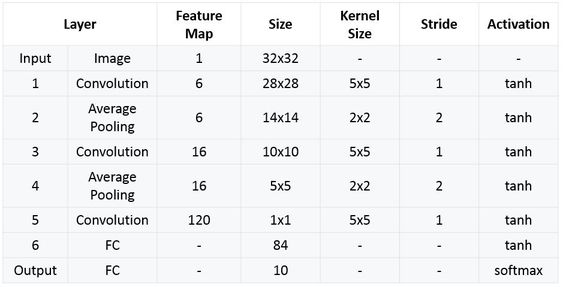

```
Sequential(
  (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flattener()
  (7): Linear(in_features=400, out_features=120, bias=True)
  (8): ReLU(inplace=True)
  (9): Linear(in_features=120, out_features=84, bias=True)
  (10): ReLU(inplace=True)
  (11): Linear(in_features=84, out_features=10, bias=True)
)
```

In [21]:
lenet_model = nn.Sequential(
    nn.Conv2d(3, 6, kernel_size=5, stride=1),      # 3x32x32 -> 6x28x28
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=2, stride=2),         # -> 6x14x14
    nn.Conv2d(6, 16, kernel_size=5, stride=1),     # -> 16x10x10
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=2, stride=2),         # -> 16x5x5
    Flattener(),                                   # -> 400
    nn.Linear(400, 120),
    nn.ReLU(inplace=True),
    nn.Linear(120, 84),
    nn.ReLU(inplace=True),
    nn.Linear(84, 10),
)

lenet_model.to(device, torch.float32)

loss = nn.CrossEntropyLoss()
optimizer = optim.SGD(lenet_model.parameters(), lr=0.02, weight_decay=1e-4)


In [22]:
loss_history, train_history, val_history = train_model(lenet_model, train_aug_loader, val_loader, loss, optimizer, 10)


Average loss: 2.065490, Train accuracy: 0.262260, Val accuracy: 0.619002
Average loss: 1.053031, Train accuracy: 0.668583, Val accuracy: 0.810525
Average loss: 0.769543, Train accuracy: 0.762857, Val accuracy: 0.848884
Average loss: 0.658167, Train accuracy: 0.794714, Val accuracy: 0.848475
Average loss: 0.601424, Train accuracy: 0.813261, Val accuracy: 0.877141
Average loss: 0.563399, Train accuracy: 0.825700, Val accuracy: 0.882329
Average loss: 0.533433, Train accuracy: 0.834778, Val accuracy: 0.877005
Average loss: 0.511211, Train accuracy: 0.841996, Val accuracy: 0.883557
Average loss: 0.494141, Train accuracy: 0.847302, Val accuracy: 0.891611
Average loss: 0.480674, Train accuracy: 0.851722, Val accuracy: 0.890724


Ожидается Val accuracy > 0.87.

### Часть 4.

Догоним и перегоним LeNet.
Сделайте изменения в сети, чтобы Val accuracy был выше.

In [23]:
best_model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    nn.Conv2d(32, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(2),                          # 32x16x16

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(inplace=True),
    nn.Conv2d(64, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(2),                          # 64x8x8

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(2),                          # 128x4x4

    Flattener(),
    nn.Linear(128 * 4 * 4, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.5),
    nn.Linear(256, 10),
)

best_model.to(device, torch.float32)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(best_model.parameters(), lr=0.001,
                             betas=(0.9, 0.999), eps=1e-08,
                             weight_decay=1e-4, amsgrad=False)
scheduler = StepLR(optimizer, step_size=5, gamma=0.5)

loss_history, train_history, val_history = train_model(
    best_model, train_aug_loader, val_loader, loss, optimizer, 10, scheduler)

/tmp/ipykernel_445/3618373730.py:7: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Average loss: 1.892744, Train accuracy: 0.316265, Val accuracy: 0.632517
Average loss: 1.406495, Train accuracy: 0.485326, Val accuracy: 0.783291
Average loss: 0.954672, Train accuracy: 0.669948, Val accuracy: 0.884923
Average loss: 0.596855, Train accuracy: 0.814132, Val accuracy: 0.908948
Average loss: 0.438803, Train accuracy: 0.872658, Val accuracy: 0.921302
Average loss: 0.376394, Train accuracy: 0.891701, Val accuracy: 0.931336
Average loss: 0.346889, Train accuracy: 0.900061, Val accuracy: 0.929971
Average loss: 0.321056, Train accuracy: 0.908235, Val accuracy: 0.931336
Average loss: 0.304314, Train accuracy: 0.912995, Val accuracy: 0.935499
Average loss: 0.266779, Train accuracy: 0.924530, Val accuracy: 0.940687


Ожидается Val accuracy > 0.88.

### Часть 5.

Проверим на тестовых данных, которые не видела модель.

In [24]:
test_loader = torch.utils.data.DataLoader(data_test, batch_size=batch_size)
final_test_accuracy = compute_accuracy(best_model, test_loader)
print("Final test accuracy - ", final_test_accuracy)

Final test accuracy -  0.9493315918869084


Ожидается final_test_accuracy > 0.88.